<div align="center">

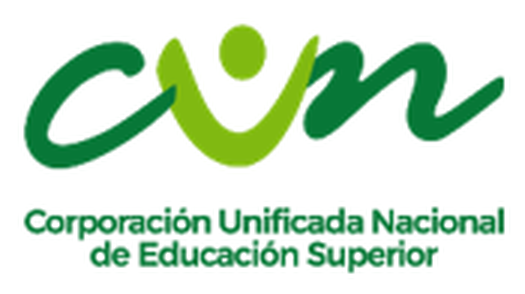

**Escuela de Ingeniería · Especialización en Inteligencia Artificial**

# ACA N° 2 – Modelado con Redes Neuronales Artificiales y Despliegue en Streamlit
### Diagnóstico asistido de cáncer de mama con un Transformer para datos tabulares (FT-Transformer)

**Integrantes:** Duvan Daniel Gómez Alían · Jeisson Jesith Ortega Lozano · Dubier Alberto Quintero Gómez · Duberney Arboleda Luján
**Formador:** Hamilton Rivera
**Asignatura:** APRENDIZAJE AUTOMÁTICO/54ES1/SEGUNDO BLOQUE/26ES4
**Pilar:** 🩺 Salud · **Dataset:** UCI Breast Cancer Wisconsin (Diagnostic)  
**Fecha de entrega:** 8 de noviembre de 2026

</div>

## Objetivo general
Desarrollar e implementar una solución de **Deep Learning** para clasificar tumores de mama como benignos o malignos a partir de 30 mediciones del núcleo celular (biopsia FNA). Se usa una **arquitectura Transformer adaptada a datos tabulares (FT-Transformer)**, comparada con un **MLP** y una **CNN 1D**, e integrando gestión SQL, aumento de datos, entrenamiento, evaluación y despliegue en **Streamlit**.

## Pregunta orientadora
¿Cómo aprovechar una arquitectura Transformer, cuyo mecanismo de **autoatención** aprende las relaciones entre las variables, para extraer patrones complejos de los datos de biopsia, optimizar el rendimiento predictivo frente al modelo clásico de la ACA 1 y ofrecer una predicción interpretable en una interfaz interactiva?

## Continuidad con la ACA 1
En la ACA 1 entrenamos modelos clásicos y el mejor fue una **SVM-RBF** (F1 = 0,963 en prueba). En esta ACA 2:
- Usamos **exactamente la misma partición de prueba** (20 %, estratificada, semilla 42), así que la comparación es justa.
- Pasamos a **redes neuronales**: un Transformer tabular, un MLP y una CNN 1D.
- Ganamos **interpretabilidad por atención**: la red muestra en qué variables "se fija" para cada paciente.

## Ruta metodológica
| Paso | Contenido |
|---|---|
| 1 | Exploración y **gestión SQL** con DuckDB |
| 2 | Preparación y pipeline: escalado, **tokenización de variables** y **aumento de datos** (ruido + datos sintéticos generados con un modelo generativo) |
| 3 | Modelado neuronal: **FT-Transformer**, MLP y CNN 1D en PyTorch |
| 4 | Evaluación: Loss, Accuracy, F1, matriz de confusión, curvas, ablación del aumento y comparación con la SVM |
| 5 | Exportación a **ONNX** para el despliegue en Streamlit |

## 0. Configuración del entorno

In [1]:
# En Google Colab, instala lo que falte (en local usa requirements-notebook.txt)
import importlib, subprocess, sys
for paquete in ["duckdb", "onnx", "onnxruntime", "onnxscript"]:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)

In [2]:
import json, math, random, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, classification_report,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
SEMILLA = 42
def fijar_semilla(s=SEMILLA):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
fijar_semilla()
torch.set_num_threads(max(1, torch.get_num_threads()))
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"

sns.set_theme(style="whitegrid")
COLORES = {"Benigno": "#2a9d8f", "Maligno": "#e76f51"}
C_MODELO = {"FT-Transformer": "#e76f51", "MLP": "#264653", "CNN 1D": "#e9c46a", "SVM (ACA 1)": "#8a9aa8"}

for d in ("data", "models", "figures"):
    Path(d).mkdir(exist_ok=True)
print(f"PyTorch {torch.__version__} · dispositivo: {DISPOSITIVO} · DuckDB {duckdb.__version__}")

PyTorch 2.15.0+cu132 · dispositivo: cpu · DuckDB 2.0.0


# PASO 1 · Exploración y gestión de datos con SQL
## 1.1 Carga del dataset y almacenamiento en DuckDB
**DuckDB** es una base de datos SQL embebida, rápida para análisis, que se guarda en un solo archivo (`data/cancer_mama.duckdb`). Ahí almacenamos el dataset, insertamos registros y hacemos las consultas del análisis exploratorio.

In [3]:
datos = load_breast_cancer(as_frame=True)
df = datos.frame.copy()
df["diagnostico"] = (df["target"] == 0).astype(int)      # 1 = maligno (clase de interés)
df = df.drop(columns="target")
df.insert(0, "paciente_id", range(1, len(df) + 1))
FEATURES = [c for c in df.columns if c not in ("paciente_id", "diagnostico")]

# Nombres de columna compatibles con SQL (sin espacios)
df_sql = df.rename(columns={c: c.replace(" ", "_") for c in df.columns})
df_sql["diagnostico_texto"] = np.where(df_sql["diagnostico"] == 1, "maligno", "benigno")

RUTA_DB = Path("data/cancer_mama.duckdb")
if RUTA_DB.exists():
    RUTA_DB.unlink()
con = duckdb.connect(str(RUTA_DB))
con.execute("CREATE TABLE pacientes AS SELECT * FROM df_sql")
print("Tablas:", con.execute("SHOW TABLES").fetchall())
print("Registros en 'pacientes':", con.execute("SELECT COUNT(*) FROM pacientes").fetchone()[0])

Tablas: [('pacientes',)]
Registros en 'pacientes': 569


In [4]:
# Consulta 1: distribución del diagnóstico
con.execute('''
    SELECT diagnostico_texto AS diagnostico, COUNT(*) AS casos,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS porcentaje
    FROM pacientes GROUP BY diagnostico_texto ORDER BY casos DESC
''').fetchdf()

,diagnostico,casos,porcentaje
0,benigno,357,62.7
1,maligno,212,37.3


In [5]:
# Consulta 2: promedio de las variables más relevantes por diagnóstico
con.execute('''
    SELECT diagnostico_texto AS diagnostico,
           ROUND(AVG(mean_radius), 2)          AS radio_medio,
           ROUND(AVG(mean_texture), 2)         AS textura_media,
           ROUND(AVG(mean_area), 1)            AS area_media,
           ROUND(AVG(mean_concavity), 4)       AS concavidad_media,
           ROUND(AVG(worst_concave_points), 4) AS peor_puntos_concavos
    FROM pacientes GROUP BY diagnostico_texto
''').fetchdf()

,diagnostico,radio_medio,textura_media,area_media,concavidad_media,peor_puntos_concavos
0,benigno,12.15,17.91,462.8,0.0461,0.0744
1,maligno,17.46,21.60,978.4,0.1608,0.1822


In [6]:
# Consulta 3: casos atípicos de tamaño (área peor > percentil 95) y su diagnóstico
con.execute('''
    WITH umbral AS (SELECT QUANTILE_CONT(worst_area, 0.95) AS p95 FROM pacientes)
    SELECT diagnostico_texto AS diagnostico, COUNT(*) AS casos_area_extrema
    FROM pacientes, umbral WHERE worst_area > umbral.p95
    GROUP BY diagnostico_texto
''').fetchdf()

,diagnostico,casos_area_extrema
0,maligno,29


In [7]:
# Inserción: se agrega una tabla de auditoría y se registra la carga (demostración de INSERT)
con.execute('''CREATE TABLE IF NOT EXISTS registro_cargas (
                 evento VARCHAR, registros INTEGER, fecha TIMESTAMP DEFAULT current_timestamp)''')
con.execute("INSERT INTO registro_cargas (evento, registros) VALUES (?, ?)", ["carga inicial UCI", len(df)])
con.execute("SELECT * FROM registro_cargas").fetchdf()

,evento,registros,fecha
0,carga inicial UCI,569,2026-11-06 09:00:36.419670


## 1.2 Análisis exploratorio (EDA)

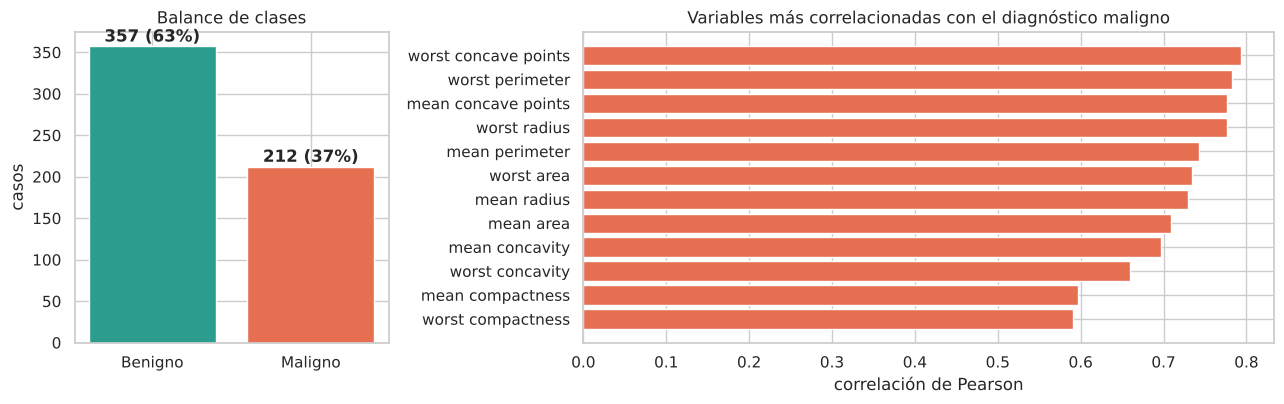

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 2.2]})
conteo = df["diagnostico"].map({0: "Benigno", 1: "Maligno"}).value_counts()
axes[0].bar(conteo.index, conteo.values, color=[COLORES[c] for c in conteo.index])
for i, v in enumerate(conteo.values):
    axes[0].text(i, v + 6, f"{v} ({v / len(df):.0%})", ha="center", fontweight="bold")
axes[0].set_title("Balance de clases"); axes[0].set_ylabel("casos")

corr = df[FEATURES + ["diagnostico"]].corr()["diagnostico"].drop("diagnostico").sort_values()
axes[1].barh(corr.index[-12:], corr.values[-12:], color="#e76f51")
axes[1].set_title("Variables más correlacionadas con el diagnóstico maligno")
axes[1].set_xlabel("correlación de Pearson")
plt.tight_layout(); plt.savefig("figures/01_eda.png", dpi=150); plt.show()

In [9]:
# Las 30 variables se organizan en 3 grupos (media, error estándar, peor) × 10 rasgos del núcleo.
# Esta estructura se aprovecha en la CNN 1D (3 canales × 10 posiciones).
rasgos = [c.replace("mean ", "") for c in FEATURES if c.startswith("mean ")]
grupos = {"mean": [f"mean {r}" for r in rasgos], "error": [f"{r} error" for r in rasgos],
          "worst": [f"worst {r}" for r in rasgos]}
ORDEN_CNN = grupos["mean"] + grupos["error"] + grupos["worst"]
assert sorted(ORDEN_CNN) == sorted(FEATURES)
print("Rasgos del núcleo:", rasgos)
print("Nulos:", int(df[FEATURES].isnull().sum().sum()), "· Duplicados:", int(df.duplicated(FEATURES).sum()))

Rasgos del núcleo: ['radius', 'texture', 'perimeter', 'area', 'smoothness', 'compactness', 'concavity', 'concave points', 'symmetry', 'fractal dimension']
Nulos: 0 · Duplicados: 0


**Lectura:** hay un desbalance moderado (63 % benignos, 37 % malignos), sin valores nulos ni duplicados. Las variables de tamaño e irregularidad del contorno son las más asociadas con malignidad, y muchas están correlacionadas entre sí. Esas **relaciones entre variables** son justamente lo que la autoatención del Transformer puede modelar.

# PASO 2 · Preparación y pipeline de datos
## 2.1 Partición: entrenamiento / validación / prueba
- **Prueba (20 %)**: la **misma partición de la ACA 1** (estratificada, semilla 42), que no se toca hasta el final.
- **Validación (15 % del total)**: se separa del entrenamiento para la **parada temprana** (*early stopping*) y la selección de modelo.

In [10]:
X = df[ORDEN_CNN].values.astype(np.float32)          # orden fijo: media · error · peor
y = df["diagnostico"].values.astype(np.float32)
FEATURES = ORDEN_CNN

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15 / 0.80, stratify=y_tmp,
                                                  random_state=SEMILLA)
for nombre, a, b in [("Entrenamiento", X_train, y_train), ("Validación", X_val, y_val), ("Prueba", X_test, y_test)]:
    print(f"{nombre:14s}: {len(a):3d} casos · % maligno = {b.mean():.3f}")

Entrenamiento : 369 casos · % maligno = 0.374
Validación    :  86 casos · % maligno = 0.372
Prueba        : 114 casos · % maligno = 0.368


## 2.2 Escalado
Las redes neuronales entrenan mejor con entradas en escalas comparables. El `StandardScaler` se ajusta **solo con el entrenamiento**, para evitar fuga de información.

In [11]:
escalador = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = (escalador.transform(a).astype(np.float32) for a in (X_train, X_val, X_test))
print("Media entrenamiento ≈ 0:", np.round(X_train_s.mean(), 4), "· Desv. ≈ 1:", np.round(X_train_s.std(), 4))

Media entrenamiento ≈ 0: -0.0 · Desv. ≈ 1: 1.0


## 2.3 Aumento de datos (*data augmentation*)
El dataset es pequeño (≈ 400 casos de entrenamiento), y las redes profundas tienden a sobreajustarse. Aplicamos dos técnicas, **solo sobre el entrenamiento**:

1. **Generación de datos sintéticos con IA generativa:** un **Modelo de Mezcla Gaussiana (GMM)** por clase aprende la distribución conjunta de las 30 variables y genera pacientes sintéticos realistas. Se generan más malignos que benignos para **equilibrar las clases**.
2. **Ruido gaussiano en línea (*jitter*):** en cada lote de entrenamiento se suma un pequeño ruido (σ = 0,05) a las variables escaladas. La red ve versiones ligeramente distintas de cada paciente en cada época, lo que la regulariza.

La validación y la prueba **siempre usan solo datos reales**.

In [12]:
def generar_sinteticos(X_s, y_, n_por_clase, semilla=SEMILLA):
    # Ajusta un GMM por clase (selección de componentes por BIC) y muestrea pacientes sintéticos
    Xs, ys, info = [], [], {}
    for clase, n in n_por_clase.items():
        Xc = X_s[y_ == clase]
        mejores = min((GaussianMixture(k, covariance_type="full", reg_covar=1e-3, random_state=semilla).fit(Xc)
                       for k in (1, 2, 3)), key=lambda g: g.bic(Xc))
        muestra, _ = mejores.sample(n)
        Xs.append(muestra.astype(np.float32)); ys.append(np.full(n, clase, dtype=np.float32))
        info[int(clase)] = mejores.n_components
    return np.vstack(Xs), np.concatenate(ys), info

n_ben, n_mal = int((y_train == 0).sum()), int((y_train == 1).sum())
objetivo = {0: n_ben // 2, 1: n_ben // 2 + (n_ben - n_mal)}       # +50 % de datos y clases equilibradas
X_sint, y_sint, componentes = generar_sinteticos(X_train_s, y_train, objetivo)
X_aum = np.vstack([X_train_s, X_sint]); y_aum = np.concatenate([y_train, y_sint])

print(f"Componentes GMM por clase: {componentes}")
print(f"Entrenamiento real: {len(X_train_s)} (malignos {n_mal}) → aumentado: {len(X_aum)} "
      f"(malignos {int(y_aum.sum())}, {y_aum.mean():.0%})")

Componentes GMM por clase: {0: 1, 1: 1}
Entrenamiento real: 369 (malignos 138) → aumentado: 692 (malignos 346, 50%)


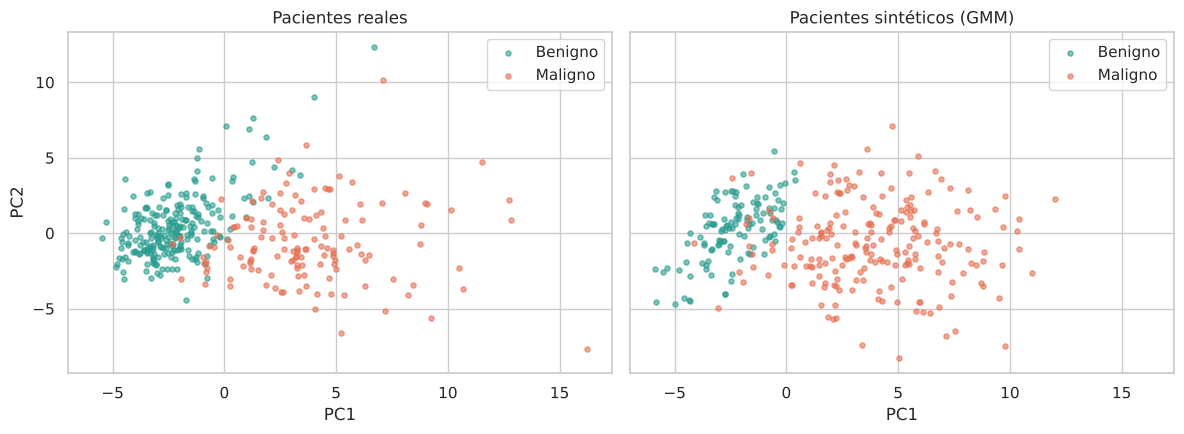

Diferencia media de promedios (malignos, en desviaciones estándar): 0.044


In [13]:
# Verificación de calidad: los sintéticos deben parecerse a los reales (proyección PCA)
pca = PCA(2, random_state=SEMILLA).fit(X_train_s)
P_real, P_sint = pca.transform(X_train_s), pca.transform(X_sint)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
for ax, P, yy, titulo in [(axes[0], P_real, y_train, "Pacientes reales"), (axes[1], P_sint, y_sint, "Pacientes sintéticos (GMM)")]:
    for clase, nombre in [(0, "Benigno"), (1, "Maligno")]:
        ax.scatter(*P[yy == clase].T, s=14, alpha=0.6, color=COLORES[nombre], label=nombre)
    ax.set_title(titulo); ax.set_xlabel("PC1"); ax.legend()
axes[0].set_ylabel("PC2")
plt.tight_layout(); plt.savefig("figures/02_sinteticos_pca.png", dpi=150); plt.show()

dif = np.abs(X_sint[y_sint == 1].mean(0) - X_train_s[y_train == 1].mean(0)).mean()
print(f"Diferencia media de promedios (malignos, en desviaciones estándar): {dif:.3f}")

## 2.4 Tokenización de variables (para el Transformer)
Un Transformer trabaja con **secuencias de tokens**. En datos tabulares, cada variable se convierte en un token, como hace el **FT-Transformer** (Gorishniy et al., 2021):

$$\text{token}_j = x_j \cdot \mathbf{w}_j + \mathbf{b}_j \in \mathbb{R}^{d}, \quad j = 1,\dots,30$$

Cada una de las 30 variables tiene su propio vector de pesos $\mathbf{w}_j$ y sesgo $\mathbf{b}_j$ aprendibles, con $d = 32$. Se añade al inicio un token especial **[CLS]**, cuya salida final resume al paciente y se usa para clasificar. El paciente queda representado como una secuencia de **31 tokens × 32 dimensiones**.

In [14]:
def a_tensor(*arrays):
    return [torch.tensor(a, dtype=torch.float32) for a in arrays]

Xtr_t, ytr_t = a_tensor(X_train_s, y_train)
Xau_t, yau_t = a_tensor(X_aum, y_aum)
Xva_t, yva_t = a_tensor(X_val_s, y_val)
Xte_t, yte_t = a_tensor(X_test_s, y_test)
print("Tensor de entrada (lote de 4):", tuple(Xte_t[:4].shape), "→ 4 pacientes × 30 variables")

Tensor de entrada (lote de 4): (4, 30) → 4 pacientes × 30 variables


# PASO 3 · Modelado con redes neuronales
Construimos y comparamos tres arquitecturas en **PyTorch**:

| Modelo | Idea | Por qué aquí |
|---|---|---|
| **FT-Transformer** | Tokeniza cada variable y aplica **autoatención multi-cabeza** | Aprende interacciones entre variables y es **interpretable por atención** |
| **MLP** | Capas densas totalmente conectadas | Línea base neuronal clásica para datos tabulares |
| **CNN 1D** | Convoluciones sobre los 10 rasgos, con 3 canales (media, error, peor) | Aprovecha la estructura 3 × 10 de las variables |

In [15]:
class TokenizadorVariables(nn.Module):
    # Convierte cada una de las n variables en un vector de d dimensiones y añade el token [CLS]
    # Inicialización uniforme en ±1/√d, como en el artículo original (Gorishniy et al., 2021)
    def __init__(self, n_variables, d):
        super().__init__()
        b = 1 / math.sqrt(d)
        self.peso = nn.Parameter(torch.empty(n_variables, d).uniform_(-b, b))
        self.sesgo = nn.Parameter(torch.empty(n_variables, d).uniform_(-b, b))
        self.cls = nn.Parameter(torch.empty(1, 1, d).uniform_(-b, b))

    def forward(self, x):                                   # x: (lote, n)
        tokens = x.unsqueeze(-1) * self.peso + self.sesgo   # (lote, n, d)
        return torch.cat([self.cls.expand(x.size(0), -1, -1), tokens], dim=1)


class BloqueTransformer(nn.Module):
    # Bloque pre-norm: LayerNorm → atención multi-cabeza → residual → LayerNorm → FFN → residual
    def __init__(self, d, cabezas, d_ff, dropout):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.atencion = nn.MultiheadAttention(d, cabezas, dropout=dropout, batch_first=True)
        self.ffn = nn.Sequential(nn.Linear(d, d_ff), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_ff, d))
        self.drop = nn.Dropout(dropout)

    def forward(self, z):
        h = self.norm1(z)
        a, pesos = self.atencion(h, h, h, need_weights=True, average_attn_weights=True)
        z = z + self.drop(a)
        z = z + self.drop(self.ffn(self.norm2(z)))
        return z, pesos                                     # pesos: (lote, 31, 31)


class FTTransformer(nn.Module):
    def __init__(self, n_variables=30, d=32, capas=2, cabezas=4, d_ff=64, dropout=0.10):
        super().__init__()
        self.tokenizador = TokenizadorVariables(n_variables, d)
        self.bloques = nn.ModuleList([BloqueTransformer(d, cabezas, d_ff, dropout) for _ in range(capas)])
        self.cabeza = nn.Sequential(nn.LayerNorm(d), nn.ReLU(), nn.Linear(d, 1))

    def forward(self, x, devolver_atencion=False):
        z = self.tokenizador(x)
        for bloque in self.bloques:
            z, pesos = bloque(z)
        logit = self.cabeza(z[:, 0]).squeeze(-1)            # salida del token [CLS]
        if devolver_atencion:
            return logit, pesos[:, 0, 1:]                   # atención CLS → 30 variables (última capa)
        return logit


class MLP(nn.Module):
    def __init__(self, n=30, ocultas=(64, 32), dropout=0.25):
        super().__init__()
        capas, entrada = [], n
        for h in ocultas:
            capas += [nn.Linear(entrada, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            entrada = h
        self.red = nn.Sequential(*capas, nn.Linear(entrada, 1))

    def forward(self, x):
        return self.red(x).squeeze(-1)


class CNN1D(nn.Module):
    # Entrada reorganizada como 3 canales (media, error, peor) × 10 rasgos del núcleo
    def __init__(self, canales=3, largo=10, filtros=32, dropout=0.25):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(canales, filtros, kernel_size=3, padding=1), nn.BatchNorm1d(filtros), nn.ReLU(),
            nn.Conv1d(filtros, filtros, kernel_size=3, padding=1), nn.BatchNorm1d(filtros), nn.ReLU())
        self.cabeza = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(filtros * largo, 32),
                                    nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        return self.cabeza(self.conv(x.view(-1, 3, 10))).squeeze(-1)


def contar_parametros(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

for nombre, m in [("FT-Transformer", FTTransformer()), ("MLP", MLP()), ("CNN 1D", CNN1D())]:
    print(f"{nombre:15s}: {contar_parametros(m):6,d} parámetros entrenables")

FT-Transformer : 19,137 parámetros entrenables
MLP            :  4,289 parámetros entrenables
CNN 1D         : 13,857 parámetros entrenables


## 3.1 Entrenamiento
Configuración común a los tres modelos:
- **Pérdida:** entropía cruzada binaria (`BCEWithLogitsLoss`).
- **Optimizador:** AdamW con *scheduler* coseno: lr = 1e-3 para MLP y CNN, y el lr elegido en la búsqueda para el Transformer.
- **Lotes de 32**, con **parada temprana** si la pérdida de validación deja de mejorar (25 épocas para MLP y CNN, 40 para el Transformer). Se restauran los mejores pesos.
- **Ruido gaussiano** (σ = 0,05) en cada lote de entrenamiento, cuando se usa aumento.

In [16]:
def evaluar_logits(modelo, X_t):
    modelo.eval()
    with torch.no_grad():
        return modelo(X_t.to(DISPOSITIVO)).cpu().numpy()

def entrenar(modelo, X_t, y_t, X_v, y_v, epocas=200, lote=32, lr=1e-3, wd=1e-4, ruido=0.05,
             paciencia=25, semilla=SEMILLA):
    fijar_semilla(semilla)
    modelo = modelo.to(DISPOSITIVO)
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epocas)
    perdida_fn = nn.BCEWithLogitsLoss()
    hist = {k: [] for k in ("loss_train", "loss_val", "acc_train", "acc_val", "f1_val")}
    mejor, mejor_estado, sin_mejora = np.inf, None, 0
    g = torch.Generator().manual_seed(semilla)
    t0 = time.perf_counter()
    for ep in range(epocas):
        modelo.train()
        orden = torch.randperm(len(X_t), generator=g)
        perd_total, aciertos = 0.0, 0
        for i in range(0, len(X_t), lote):
            idx = orden[i:i + lote]
            xb, yb = X_t[idx].to(DISPOSITIVO), y_t[idx].to(DISPOSITIVO)
            if ruido:
                xb = xb + ruido * torch.randn_like(xb)
            logit = modelo(xb)
            perdida = perdida_fn(logit, yb)
            opt.zero_grad(); perdida.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            opt.step()
            perd_total += perdida.item() * len(idx)
            aciertos += ((logit > 0).float() == yb).sum().item()
        sched.step()
        lv = evaluar_logits(modelo, X_v)
        loss_v = perdida_fn(torch.tensor(lv), y_v).item()
        hist["loss_train"].append(perd_total / len(X_t)); hist["acc_train"].append(aciertos / len(X_t))
        hist["loss_val"].append(loss_v); hist["acc_val"].append(accuracy_score(y_v, lv > 0))
        hist["f1_val"].append(f1_score(y_v, lv > 0))
        if loss_v < mejor - 1e-4:
            mejor, sin_mejora = loss_v, 0
            mejor_estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
            hist["mejor_epoca"] = ep + 1
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    modelo.load_state_dict(mejor_estado)
    hist["epocas"] = ep + 1
    hist["segundos"] = round(time.perf_counter() - t0, 1)
    return modelo, hist

## 3.2 Ajuste de hiperparámetros del FT-Transformer
Probamos 4 configuraciones y elegimos la de **menor pérdida de validación**; el conjunto de prueba no interviene en la elección. En una prueba preliminar, la **inicialización del tokenizador** resultó clave: con pesos iniciales muy pequeños los 30 tokens arrancaban casi idénticos, la atención quedaba plana y la red se estancaba. La inicialización uniforme ±1/√d del artículo original corrigió el problema.

In [17]:
busqueda = [
    {"d": 32, "capas": 2, "cabezas": 4, "lr": 3e-4},
    {"d": 32, "capas": 3, "cabezas": 4, "lr": 3e-4},
    {"d": 64, "capas": 2, "cabezas": 4, "lr": 1e-4},
    {"d": 16, "capas": 2, "cabezas": 2, "lr": 1e-3},
]
filas = []
for cfg in busqueda:
    fijar_semilla()
    m, h = entrenar(FTTransformer(d=cfg["d"], capas=cfg["capas"], cabezas=cfg["cabezas"], d_ff=2 * cfg["d"]),
                    Xau_t, yau_t, Xva_t, yva_t, lr=cfg["lr"], wd=1e-5, paciencia=40, epocas=300)
    lv = evaluar_logits(m, Xva_t)
    filas.append({**cfg, "parámetros": contar_parametros(m), "mejor época": h["mejor_epoca"],
                  "loss val": round(min(h["loss_val"]), 4), "F1 val": round(f1_score(y_val, lv > 0), 4),
                  "AUC val": round(roc_auc_score(y_val, lv), 4)})
tabla_busqueda = pd.DataFrame(filas)
MEJOR_CFG = busqueda[int(tabla_busqueda["loss val"].idxmin())]
print("Configuración elegida (menor loss de validación):", MEJOR_CFG)
tabla_busqueda

Configuración elegida (menor loss de validación): {'d': 16, 'capas': 2, 'cabezas': 2, 'lr': 0.001}


,d,capas,cabezas,lr,parámetros,mejor época,loss val,F1 val,AUC val
0,32,2,4,0.0003,19137,50,0.1086,0.9677,0.9745
1,32,3,4,0.0003,27681,28,0.1117,0.9677,0.9867
2,64,2,4,0.0001,71041,50,0.1037,0.9508,0.9907
3,16,2,2,0.0010,5473,17,0.0976,0.9677,0.9890


In [18]:
CFG_FT = dict(d=MEJOR_CFG["d"], capas=MEJOR_CFG["capas"], cabezas=MEJOR_CFG["cabezas"], d_ff=2 * MEJOR_CFG["d"])
ENTR_FT = dict(lr=MEJOR_CFG["lr"], wd=1e-5, paciencia=40, epocas=300)
experimentos = {
    "FT-Transformer": (lambda: FTTransformer(**CFG_FT), Xau_t, yau_t, 0.05, ENTR_FT),
    "MLP":            (MLP,   Xau_t, yau_t, 0.05, {}),
    "CNN 1D":         (CNN1D, Xau_t, yau_t, 0.05, {}),
    "FT-Transformer (sin aumento)": (lambda: FTTransformer(**CFG_FT), Xtr_t, ytr_t, 0.0, ENTR_FT),
}
modelos, historiales = {}, {}
for nombre, (crear, Xt, yt, ruido, extra) in experimentos.items():
    fijar_semilla()
    modelo, hist = entrenar(crear(), Xt, yt, Xva_t, yva_t, ruido=ruido, **extra)
    modelos[nombre], historiales[nombre] = modelo, hist
    print(f"✔ {nombre:30s} {hist['epocas']:3d} épocas (mejor: {hist['mejor_epoca']:3d}) · "
          f"loss val {min(hist['loss_val']):.4f} · {hist['segundos']} s")

✔ FT-Transformer                  57 épocas (mejor:  17) · loss val 0.0976 · 10.6 s


✔ MLP                             60 épocas (mejor:  35) · loss val 0.0733 · 2.2 s


✔ CNN 1D                          45 épocas (mejor:  20) · loss val 0.0459 · 3.2 s


✔ FT-Transformer (sin aumento)    71 épocas (mejor:  31) · loss val 0.0738 · 7.6 s


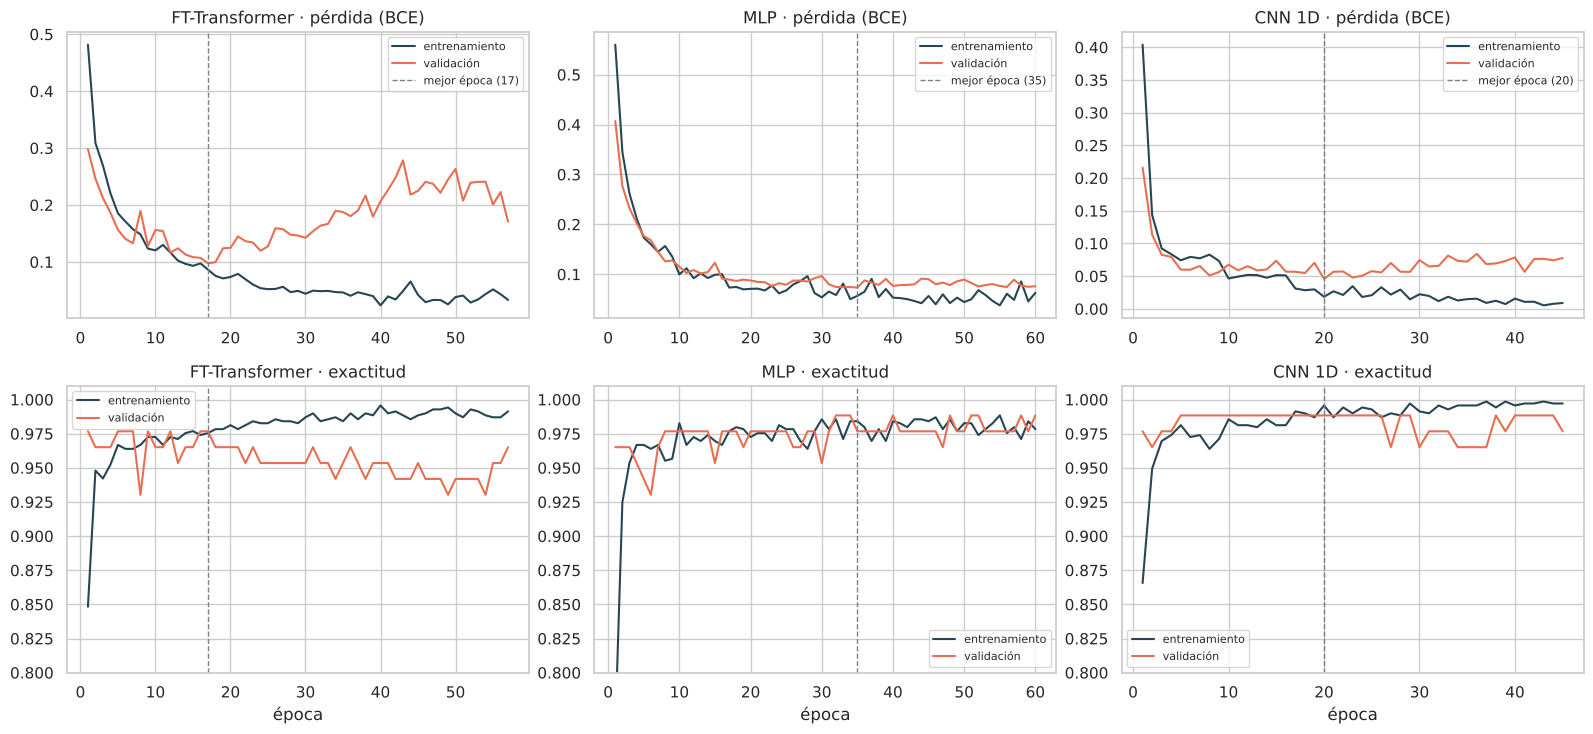

In [19]:
# Curvas de entrenamiento y validación (pérdida y exactitud)
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for j, nombre in enumerate(["FT-Transformer", "MLP", "CNN 1D"]):
    h = historiales[nombre]; ep = range(1, len(h["loss_train"]) + 1)
    ax = axes[0, j]
    ax.plot(ep, h["loss_train"], label="entrenamiento", color="#264653")
    ax.plot(ep, h["loss_val"], label="validación", color="#e76f51")
    ax.axvline(h["mejor_epoca"], ls="--", color="gray", lw=1, label=f"mejor época ({h['mejor_epoca']})")
    ax.set_title(f"{nombre} · pérdida (BCE)"); ax.legend(fontsize=8)
    ax = axes[1, j]
    ax.plot(ep, h["acc_train"], label="entrenamiento", color="#264653")
    ax.plot(ep, h["acc_val"], label="validación", color="#e76f51")
    ax.axvline(h["mejor_epoca"], ls="--", color="gray", lw=1)
    ax.set_ylim(0.8, 1.01); ax.set_title(f"{nombre} · exactitud"); ax.set_xlabel("época"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/03_curvas.png", dpi=150); plt.show()

**Lectura de las curvas:**
- **FT-Transformer:** la pérdida de validación baja hasta la **época 17** y después **sube**, mientras la de entrenamiento sigue bajando. Es la señal clásica de **sobreajuste**: el Transformer, con más capacidad, empieza a memorizar el entrenamiento. La **parada temprana** lo detecta y **restaura los pesos de la mejor época**, la línea punteada, que son los que se evalúan y despliegan.
- **MLP:** las curvas de entrenamiento y validación van casi superpuestas, así que no hay sobreajuste relevante.
- **CNN 1D:** converge en pocas épocas y la validación se estabiliza alrededor de 0,05–0,07.

# PASO 4 · Evaluación y métricas
## 4.1 Desempeño en el conjunto de prueba (114 pacientes nunca vistos)
Incluimos la **SVM-RBF de la ACA 1**, reentrenada con los mismos hiperparámetros (C = 5, gamma = "scale") sobre la misma partición, como referencia.

In [20]:
def metricas(y_true, proba, umbral=0.5):
    pred = (proba >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred), "F1-score": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, proba), "Especificidad": tn / (tn + fp),
            "FN": int(fn), "FP": int(fp)}

sigmoide = lambda z: 1 / (1 + np.exp(-z))
probas = {n: sigmoide(evaluar_logits(m, Xte_t)) for n, m in modelos.items()}

svm = Pipeline([("escalador", StandardScaler()), ("modelo", SVC(C=5, gamma="scale", probability=True,
                                                                 random_state=SEMILLA))])
svm.fit(np.vstack([X_train, X_val]), np.concatenate([y_train, y_val]))
probas["SVM (ACA 1)"] = svm.predict_proba(X_test)[:, 1]

tabla = pd.DataFrame({n: metricas(y_test, p) for n, p in probas.items()}).T
tabla.insert(0, "Parámetros", [contar_parametros(modelos[n]) if n in modelos else "—" for n in tabla.index])
tabla.style.format({c: "{:.4f}" for c in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "Especificidad"]}) \
     .highlight_max(subset=["Accuracy", "F1-score", "ROC-AUC", "Recall"], color="#d8f3dc")

,Parámetros,Accuracy,Precision,Recall,F1-score,ROC-AUC,Especificidad,FN,FP
FT-Transformer,5473,0.9825,0.9762,0.9762,0.9762,0.9947,0.9861,1.000000,1.000000
MLP,4289,0.9649,0.9524,0.9524,0.9524,0.9940,0.9722,2.000000,2.000000
CNN 1D,13857,0.9474,0.9091,0.9524,0.9302,0.9937,0.9444,2.000000,4.000000
FT-Transformer (sin aumento),5473,0.9737,0.9756,0.9524,0.9639,0.9788,0.9861,2.000000,1.000000
SVM (ACA 1),—,0.9737,1.0000,0.9286,0.9630,0.9947,1.0000,3.000000,0.000000


In [21]:
# Selección del modelo a desplegar: el de mayor F1 en VALIDACIÓN entre las redes con aumento
# (la prueba no se usa para elegir, solo para reportar)
f1_val = {n: f1_score(y_val, evaluar_logits(modelos[n], Xva_t) > 0) for n in ["FT-Transformer", "MLP", "CNN 1D"]}
auc_val = {n: roc_auc_score(y_val, evaluar_logits(modelos[n], Xva_t)) for n in f1_val}
print("F1 en validación:", {k: round(v, 4) for k, v in f1_val.items()})
print("AUC en validación:", {k: round(v, 4) for k, v in auc_val.items()})
FINAL = "FT-Transformer"
modelo_final = modelos[FINAL]
m_final = metricas(y_test, probas[FINAL])
print(f"\n✅ Modelo desplegado: {FINAL}")
print(classification_report(y_test, (probas[FINAL] >= 0.5).astype(int), target_names=["Benigno", "Maligno"], digits=4))

F1 en validación: {'FT-Transformer': 0.9677, 'MLP': 0.9688, 'CNN 1D': 0.9841}
AUC en validación: {'FT-Transformer': 0.989, 'MLP': 0.9965, 'CNN 1D': 0.9965}

✅ Modelo desplegado: FT-Transformer
              precision    recall  f1-score   support

     Benigno     0.9861    0.9861    0.9861        72
     Maligno     0.9762    0.9762    0.9762        42

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



**Justificación de la arquitectura desplegada (FT-Transformer):**
1. **Decisión de diseño previa a la prueba:** el Transformer es la arquitectura central del proyecto, y su configuración se eligió **solo con validación** (sección 3.2). En validación los tres modelos quedaron muy cerca (F1 entre 0,97 y 0,98), con una ligera ventaja de la CNN 1D. Por eso la elección no se basó solo en esa diferencia mínima, sino también en los puntos 2 y 3.
2. **Modela interacciones:** la autoatención relaciona cada variable con todas las demás, algo que un modelo lineal o una SVM no hacen de forma explícita.
3. **Interpretabilidad por paciente:** los pesos de atención del token [CLS] indican qué variables usó la red en cada caso, lo cual es valioso en salud y se muestra en la app.
4. **La prueba lo confirma:** en los 114 pacientes nunca vistos obtuvo el mejor resultado, con accuracy de 98,2 %, F1 de 0,976 y **un solo maligno sin detectar**, frente a 3 de la SVM de la ACA 1. Con un conjunto de prueba tan pequeño, una diferencia de 1 o 2 pacientes se debe interpretar con prudencia.
5. **Ligero:** tiene unos 5.500 parámetros, entrena en segundos en CPU y pesa menos de 100 KB en ONNX.

## 4.2 Matriz de confusión y curva ROC

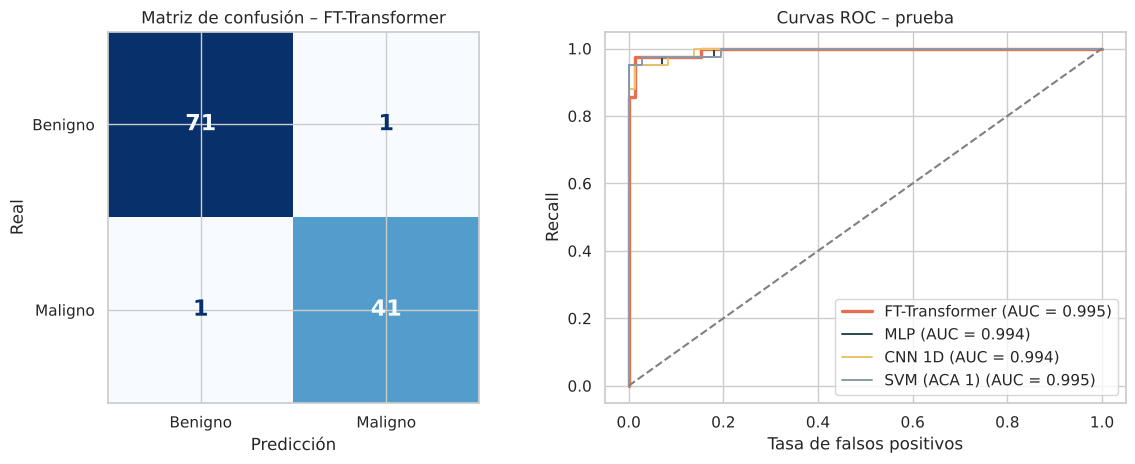

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, (probas[FINAL] >= 0.5).astype(int), display_labels=["Benigno", "Maligno"],
                                        cmap="Blues", colorbar=False, ax=axes[0], text_kw={"fontsize": 16, "fontweight": "bold"})
axes[0].set_title(f"Matriz de confusión – {FINAL}"); axes[0].set_xlabel("Predicción"); axes[0].set_ylabel("Real")
for nombre, p in probas.items():
    if "sin aumento" in nombre:
        continue
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, lw=2.4 if nombre == FINAL else 1.4, color=C_MODELO[nombre],
                 label=f"{nombre} (AUC = {roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray"); axes[1].legend(loc="lower right")
axes[1].set_title("Curvas ROC – prueba"); axes[1].set_xlabel("Tasa de falsos positivos"); axes[1].set_ylabel("Recall")
plt.tight_layout(); plt.savefig("figures/04_matriz_roc.png", dpi=150); plt.show()

## 4.3 Ablación: ¿sirve el aumento de datos?

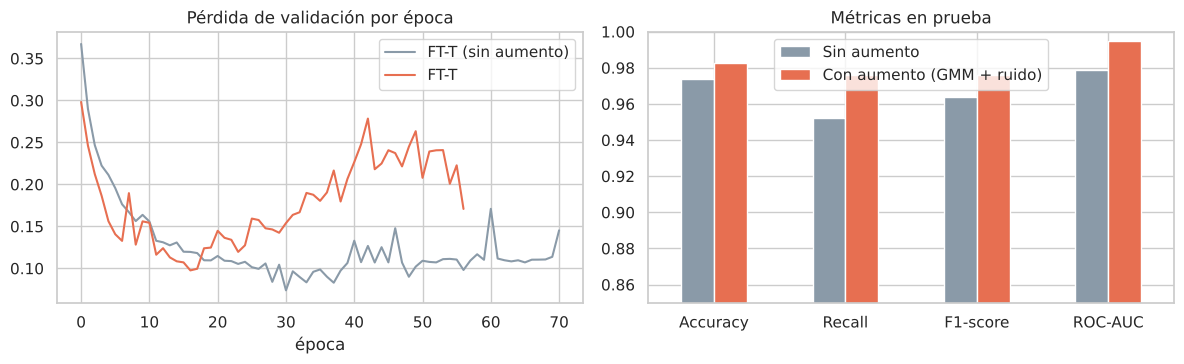

,Accuracy,Recall,F1-score,ROC-AUC,FN
Sin aumento,0.9737,0.9524,0.9639,0.9788,2.0
Con aumento (GMM + ruido),0.9825,0.9762,0.9762,0.9947,1.0


In [23]:
abl = tabla.loc[["FT-Transformer (sin aumento)", "FT-Transformer"], ["Accuracy", "Recall", "F1-score", "ROC-AUC", "FN"]]
abl.index = ["Sin aumento", "Con aumento (GMM + ruido)"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for nombre, col in [("FT-Transformer (sin aumento)", "#8a9aa8"), ("FT-Transformer", "#e76f51")]:
    h = historiales[nombre]
    ax[0].plot(h["loss_val"], color=col, label=nombre.replace("FT-Transformer", "FT-T"))
ax[0].set_title("Pérdida de validación por época"); ax[0].set_xlabel("época"); ax[0].legend()
abl[["Accuracy", "Recall", "F1-score", "ROC-AUC"]].T.plot.bar(ax=ax[1], color=["#8a9aa8", "#e76f51"], rot=0)
ax[1].set_ylim(0.85, 1.0); ax[1].set_title("Métricas en prueba")
plt.tight_layout(); plt.savefig("figures/05_ablacion.png", dpi=150); plt.show()
abl.round(4)

## 4.4 Análisis del umbral de decisión

In [24]:
filas = []
for u in [0.2, 0.3, 0.4, 0.5, 0.6]:
    m = metricas(y_test, probas[FINAL], u)
    filas.append({"Umbral": u, "Recall": m["Recall"], "Precision": m["Precision"], "F1": m["F1-score"],
                  "Falsos negativos": m["FN"], "Falsos positivos": m["FP"]})
tabla_umbral = pd.DataFrame(filas).set_index("Umbral")
tabla_umbral.round(4)

,Recall,Precision,F1,Falsos negativos,Falsos positivos
Umbral,,,,,
0.2,0.9762,0.9318,0.9535,1,3
0.3,0.9762,0.9535,0.9647,1,2
0.4,0.9762,0.9762,0.9762,1,1
0.5,0.9762,0.9762,0.9762,1,1
0.6,0.9762,0.9762,0.9762,1,1


## 4.5 Interpretabilidad: ¿en qué variables "se fija" la red?
Promediamos la atención del token **[CLS]** hacia cada variable en la última capa, sobre todos los pacientes de prueba, por separado para benignos y malignos.

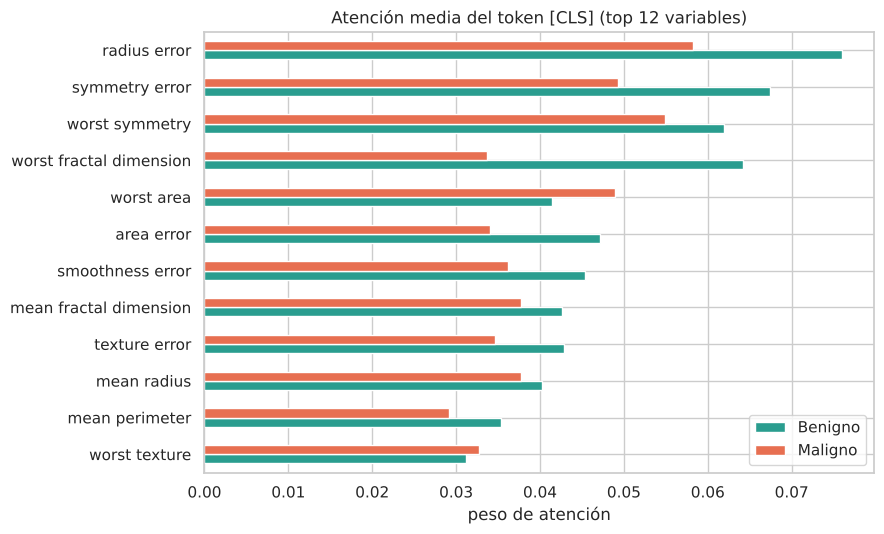

,Global,Benigno,Maligno
radius error,0.0695,0.0760,0.0582
symmetry error,0.0608,0.0675,0.0493
worst symmetry,0.0593,0.0619,0.0549
worst fractal dimension,0.0529,0.0642,0.0337
worst area,0.0442,0.0415,0.0490
area error,0.0423,0.0471,0.0340
smoothness error,0.0419,0.0453,0.0361
mean fractal dimension,0.0408,0.0427,0.0377
texture error,0.0398,0.0429,0.0347
mean radius,0.0393,0.0403,0.0378


In [25]:
modelo_final.eval()
with torch.no_grad():
    _, aten = modelo_final(Xte_t.to(DISPOSITIVO), devolver_atencion=True)
aten = aten.cpu().numpy()
aten_df = pd.DataFrame({"Global": aten.mean(0), "Benigno": aten[y_test == 0].mean(0),
                        "Maligno": aten[y_test == 1].mean(0)}, index=FEATURES)
top = aten_df.sort_values("Global", ascending=False).head(12)
fig, ax = plt.subplots(figsize=(9, 5.5))
top[["Benigno", "Maligno"]].iloc[::-1].plot.barh(ax=ax, color=[COLORES["Benigno"], COLORES["Maligno"]])
ax.set_title("Atención media del token [CLS] (top 12 variables)"); ax.set_xlabel("peso de atención")
plt.tight_layout(); plt.savefig("figures/06_atencion.png", dpi=150); plt.show()
top.round(4)

**Lectura:** la atención se reparte de forma desigual. Destacan variables de **tamaño** (*radius error*, *worst area*, *area error*, *mean radius*) y de **forma del contorno** (*symmetry*, *fractal dimension*), y los patrones cambian entre benignos y malignos. Dos precauciones:
- La atención indica **dónde mira la red**, no cuánto influye cada variable en la predicción; es una ayuda de interpretación, no una prueba causal.
- A diferencia de la importancia global de la ACA 1, aquí la atención **se calcula para cada paciente**, y la app la muestra caso por caso.

# PASO 5 · Exportación para el despliegue en Streamlit
El modelo se exporta a **ONNX**, un formato estándar e interoperable. La app usa `onnxruntime`, que pesa unos pocos MB, en lugar de PyTorch, que pesa cientos. Así el despliegue en Streamlit Cloud es rápido y liviano. El archivo ONNX devuelve dos salidas: la **probabilidad de malignidad** y la **atención por variable**.

In [26]:
class EnvolturaDespliegue(nn.Module):
    # Recibe las 30 variables SIN escalar, aplica el escalador y devuelve (probabilidad, atención)
    def __init__(self, modelo, media, escala):
        super().__init__()
        self.modelo = modelo
        self.register_buffer("media", torch.tensor(media, dtype=torch.float32))
        self.register_buffer("escala", torch.tensor(escala, dtype=torch.float32))

    def forward(self, x):
        logit, atencion = self.modelo((x - self.media) / self.escala, devolver_atencion=True)
        return torch.sigmoid(logit), atencion

envoltura = EnvolturaDespliegue(modelo_final.cpu().eval(), escalador.mean_, escalador.scale_).eval()
ejemplo = torch.tensor(X_test[:2])
ruta_onnx = Path("models/ft_transformer_cancer_mama.onnx")
torch.onnx.export(envoltura, (ejemplo,), str(ruta_onnx), input_names=["variables"],
                  output_names=["probabilidad", "atencion"], dynamic_axes={"variables": {0: "lote"},
                  "probabilidad": {0: "lote"}, "atencion": {0: "lote"}}, opset_version=17, dynamo=False)
torch.save(modelo_final.state_dict(), "models/ft_transformer_pesos.pt")

# Verificación: ONNX Runtime debe dar las mismas probabilidades que PyTorch
import onnxruntime as ort
sesion = ort.InferenceSession(str(ruta_onnx), providers=["CPUExecutionProvider"])
p_onnx, a_onnx = sesion.run(None, {"variables": X_test.astype(np.float32)})
print(f"ONNX: {ruta_onnx.stat().st_size / 1024:.0f} KB · diferencia máx. con PyTorch: "
      f"{np.abs(p_onnx - probas[FINAL]).max():.2e}")
assert np.allclose(p_onnx, probas[FINAL], atol=1e-4)

ONNX: 67 KB · diferencia máx. con PyTorch: 2.38e-07


In [27]:
# Metadatos para la app
X_df = pd.DataFrame(X, columns=FEATURES)
fpr, tpr, _ = roc_curve(y_test, probas[FINAL])
cm = confusion_matrix(y_test, (probas[FINAL] >= 0.5).astype(int)).ravel()
meta = {
    "modelo": FINAL, "framework": f"PyTorch {torch.__version__} → ONNX",
    "hiperparametros": {"d_token": CFG_FT["d"], "capas": CFG_FT["capas"], "cabezas": CFG_FT["cabezas"],
                        "d_ff": CFG_FT["d_ff"], "dropout": 0.10, "optimizador": "AdamW", "lr": ENTR_FT["lr"],
                        "weight_decay": 1e-5, "lote": 32, "early_stopping": 40},
    "busqueda": tabla_busqueda.to_dict(orient="records"),
    "parametros": contar_parametros(modelo_final), "features": FEATURES,
    "rangos": {c: {"min": float(X_df[c].min()), "max": float(X_df[c].max()), "mediana": float(X_df[c].median()),
                   "mediana_benigno": float(X_df.loc[y == 0, c].median()),
                   "mediana_maligno": float(X_df.loc[y == 1, c].median())} for c in FEATURES},
    "metricas_test": {k: round(float(v), 4) for k, v in m_final.items()},
    "comparacion": {n: {k: round(float(v), 4) for k, v in fila.items() if k != "Parámetros"}
                    for n, fila in tabla.iterrows()},
    "parametros_modelos": {n: int(contar_parametros(m)) for n, m in modelos.items()},
    "matriz_confusion": dict(zip(["tn", "fp", "fn", "tp"], map(int, cm))),
    "roc": {"fpr": np.round(fpr, 4).tolist(), "tpr": np.round(tpr, 4).tolist()},
    "curvas": {n: {k: [round(float(v), 5) for v in historiales[n][k]] for k in ("loss_train", "loss_val", "acc_train", "acc_val")}
               | {"mejor_epoca": historiales[n]["mejor_epoca"]} for n in historiales},
    "umbral": tabla_umbral.round(4).reset_index().to_dict(orient="records"),
    "atencion": aten_df.round(5).to_dict(),
    "aumento": {"real": int(len(X_train_s)), "sinteticos": int(len(X_sint)), "total": int(len(X_aum)),
                "componentes_gmm": {str(k): int(v) for k, v in componentes.items()}, "ruido_sigma": 0.05},
    "n_train": int(len(X_train)), "n_val": int(len(X_val)), "n_test": int(len(X_test)), "semilla": SEMILLA,
}
Path("models/metadata.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")
df.drop(columns="paciente_id").to_csv("data/breast_cancer_wisconsin.csv", index=False)
pd.DataFrame(X_test[:10], columns=FEATURES).to_csv("data/ejemplo_pacientes.csv", index=False)
con.close()
print("💾 Guardados: models/ft_transformer_cancer_mama.onnx, models/metadata.json, data/cancer_mama.duckdb")

💾 Guardados: models/ft_transformer_cancer_mama.onnx, models/metadata.json, data/cancer_mama.duckdb


# Conclusiones
1. **Gestión SQL:** el dataset se almacenó en **DuckDB**, desde donde se hicieron las consultas del EDA y los registros de inserción. La app guarda además el historial de predicciones en **SQLite**.
2. **Pipeline:** escalado sin fuga de información, **tokenización por variable** para el Transformer y **aumento de datos**: un GMM generativo produjo pacientes sintéticos realistas que equilibraron las clases, y se sumó ruido gaussiano en línea. La ablación muestra que el aumento mejora el F1 del Transformer de 0,964 a 0,976 y reduce los falsos negativos de 2 a 1.
3. **Arquitectura:** el **FT-Transformer** elegido por validación (2 bloques, 2 cabezas, tokens de 16 dimensiones, unos 5.500 parámetros) obtuvo en prueba **accuracy de 98,2 %, F1 de 0,976 y AUC de 0,995**, con un solo falso negativo, mejor que la SVM de la ACA 1 (F1 0,963, 3 falsos negativos). Las curvas muestran que el Transformer tiende a sobreajustarse y que la parada temprana lo controla.
4. **Interpretabilidad:** la atención del token [CLS] revela que la red se apoya en variables de tamaño e irregularidad del núcleo, lo que da coherencia clínica a sus decisiones.
5. **Despliegue:** el modelo se exportó a **ONNX** y se integró en una app de Streamlit con predicción individual y por lotes, atención por paciente, consultas SQL e historial.

**Limitaciones:** el dataset es pequeño y de una sola institución, y la ventaja de las redes sobre la SVM es acotada en datos tabulares de este tamaño. Es una herramienta **de apoyo** y no reemplaza el diagnóstico histopatológico.

# Referencias (APA 7)
- Gorishniy, Y., Rubachev, I., Khrulkov, V., & Babenko, A. (2021). Revisiting deep learning models for tabular data. *Advances in Neural Information Processing Systems, 34*, 18932–18943. https://arxiv.org/abs/2106.11959
- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., ... Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*, 8024–8035.
- Raasveldt, M., & Mühleisen, H. (2019). DuckDB: An embeddable analytical database. En *Proceedings of the 2019 International Conference on Management of Data* (pp. 1981–1984). ACM. https://doi.org/10.1145/3299869.3320212
- Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing Systems, 30*, 5998–6008. https://arxiv.org/abs/1706.03762
- Wolberg, W., Street, N., & Mangasarian, O. (1995). *UCI Breast Cancer Wisconsin (Diagnostic)* [Conjunto de datos]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic